# Exploratory Data Analysis — bina.az Sale Listings
**MLE-AI-201 · Final Project**

Sections:
1. Dataset Overview
2. Price Distribution (raw + log scale)
3. Geospatial Map (lat/lng coloured by price)
4. Missing-Value Heatmap
5. Outlier Box Plots
6. Feature Correlation Matrix
7. Price by City & Top Baku Districts
8. Price-Tier Class Balance (Task B)
9. Price vs Area & Rooms
10. EDA Takeaways

In [20]:
import sys, os
sys.path.insert(0, os.path.join(os.getcwd(), '..'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

SEED = 42
np.random.seed(SEED)

FIG_DIR = '../report/figures'
os.makedirs(FIG_DIR, exist_ok=True)

plt.rcParams.update({
    'figure.dpi': 120,
    'font.family': 'DejaVu Sans',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.3,
})
PALETTE = ['#4C72B0', '#DD8452', '#55A868', '#C44E52', '#8172B2']
print('Setup done!')

Setup done!


## 1. Dataset Overview

In [21]:
RAW_PATH = '../data/bina_az_sale.csv'
df_raw = pd.read_csv(RAW_PATH, low_memory=False)
print(f'Shape : {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns')
print(f'Memory: {df_raw.memory_usage(deep=True).sum() / 1e6:.1f} MB')
df_raw.head(3) 

Shape : 100,775 rows x 51 columns
Memory: 172.2 MB


,id_x,rel_url,estate_rel_url_x,datetime_scrape_x,price,currency_x,location,attributes,city_when,city,...,Mərtəbə,Otaq sayı,Sahə,Torpaq sahəsi,Təmir,Çıxarış,İpoteka,estate_details_id_y,estate_rel_url,extra_info
0,5df36281-6dc6-4d5d-89a7-5fcfa86f7608,/alqi-satqi?page=174,/items/4521724,2024-10-05 22:07:37.60613+00,499999.0,AZN,Səbail r.,"4 otaqlı, 145 m², 7/9 mərtəbə","Bakı, dünən 23:52",bakı,...,7 / 9,4.0,145 m²,NaN,var,var,NaN,92e82ea2-e1f3-4c2d-a284-151efd99281e,/items/4521724,Şəhidlər xiyabanı * Dağüstü parkı * Səbail r.
1,883e20f0-8872-49a5-8b4b-63b8301b5f8f,/alqi-satqi?page=250,/items/4669294,2024-10-05 22:07:37.60613+00,77000.0,AZN,Biləcəri q.,"4 otaqlı, 90 m²","Bakı, dünən 23:56",bakı,...,NaN,4.0,90 m²,1.3 sot,var,yoxdur,NaN,505eaf81-6bc8-4094-9b00-aa82066548ee,/items/4669294,Binəqədi r.* Biləcəri q.
2,55c36fb1-a3af-476e-ba17-a81f6795be8d,/alqi-satqi?page=250,/items/4669293,2024-10-05 22:07:37.60613+00,92000.0,AZN,İnşaatçılar m.,"3 otaqlı, 60 m²","Bakı, dünən 23:55",bakı,...,NaN,3.0,60 m²,0.1 sot,var,var,NaN,fa63b201-999d-43b5-a61a-778d9d79a6c6,/items/4669293,İnşaatçılar m.* Yasamal r.


In [22]:
print('Key numeric stats:')
display(df_raw[['price', 'lat', 'lng', 'views', 'unit_price']].describe().round(2))

Key numeric stats:


,price,lat,lng,views
count,1.007750e+05,100775.00,100775.00,100775.00
mean,3.423557e+05,40.41,49.89,700.07
std,2.042627e+06,0.08,0.27,1680.67
min,1.100000e+01,32.69,12.59,23.00
25%,1.450000e+05,40.38,49.82,99.00
50%,2.180000e+05,40.40,49.85,254.00
75%,3.380000e+05,40.42,49.95,680.00
max,6.000000e+08,41.77,50.34,113458.00


## 2. Price Distribution (Raw + Log Scale)

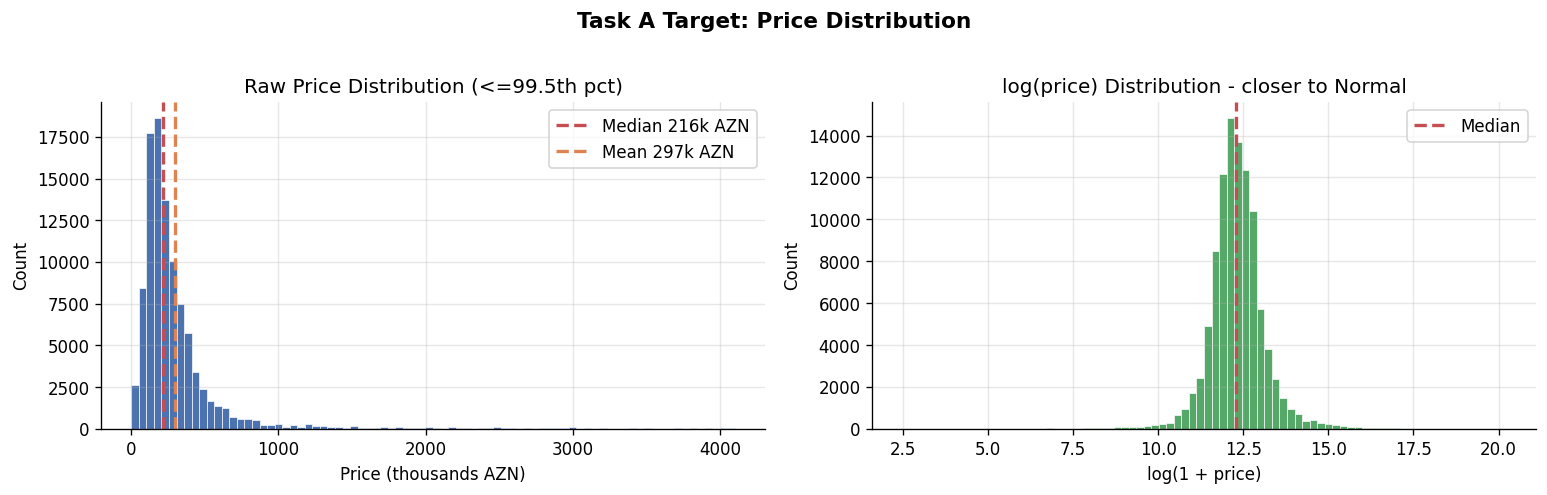

Raw skewness: 252.31 | log skewness: 0.16


In [23]:
prices = df_raw['price'].dropna().astype(float)
prices_vis = prices[prices <= prices.quantile(0.995)]
log_prices = np.log1p(prices)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(prices_vis / 1e3, bins=80, color=PALETTE[0], edgecolor='white', linewidth=0.4)
axes[0].axvline(prices_vis.median() / 1e3, color=PALETTE[3], lw=2, linestyle='--',
                label=f'Median {prices_vis.median()/1e3:.0f}k AZN')
axes[0].axvline(prices_vis.mean() / 1e3, color=PALETTE[1], lw=2, linestyle='--',
                label=f'Mean {prices_vis.mean()/1e3:.0f}k AZN')
axes[0].set_xlabel('Price (thousands AZN)')
axes[0].set_ylabel('Count')
axes[0].set_title('Raw Price Distribution (<=99.5th pct)')
axes[0].legend()

axes[1].hist(log_prices, bins=80, color=PALETTE[2], edgecolor='white', linewidth=0.4)
axes[1].axvline(np.log1p(prices.median()), color=PALETTE[3], lw=2, linestyle='--', label='Median')
axes[1].set_xlabel('log(1 + price)')
axes[1].set_ylabel('Count')
axes[1].set_title('log(price) Distribution - closer to Normal')
axes[1].legend()

fig.suptitle('Task A Target: Price Distribution', fontsize=13, fontweight='bold', y=1.02)
fig.tight_layout()
fig.savefig(f'{FIG_DIR}/price_distribution.png', bbox_inches='tight', dpi=150)
plt.show()
print(f'Raw skewness: {prices.skew():.2f} | log skewness: {log_prices.skew():.2f}')

## 3. Geospatial Map — Listings Coloured by Price

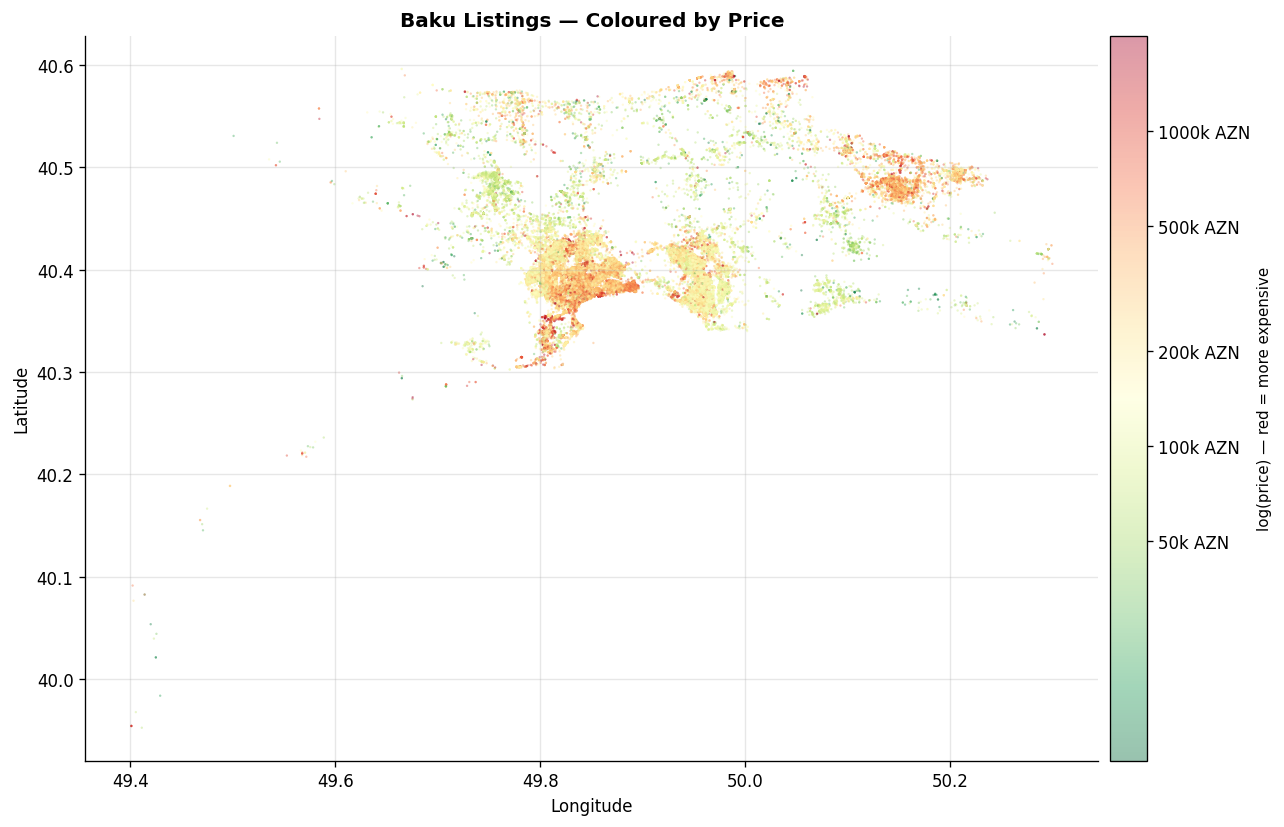

Points shown: 98,946


In [24]:
geo = df_raw[['lat', 'lng', 'price']].dropna()
geo = geo[
    geo['lat'].between(39.9, 40.6) &
    geo['lng'].between(49.4, 50.3) &
    geo['price'].between(10_000, 2_000_000)
]

fig, ax = plt.subplots(figsize=(11, 7))
sc = ax.scatter(geo['lng'], geo['lat'],
               c=np.log1p(geo['price']), cmap='RdYlGn_r',
               s=2, alpha=0.4, linewidths=0)
cbar = fig.colorbar(sc, ax=ax, pad=0.01)
cbar.set_label('log(price) — red = more expensive', fontsize=9)
tick_vals = [50_000, 100_000, 200_000, 500_000, 1_000_000]
cbar.set_ticks([np.log1p(v) for v in tick_vals])
cbar.set_ticklabels([f'{v//1000}k AZN' for v in tick_vals])
ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude')
ax.set_title('Baku Listings — Coloured by Price', fontweight='bold')
fig.tight_layout()
fig.savefig(f'{FIG_DIR}/geospatial_price_map.png', bbox_inches='tight', dpi=150)
plt.show()
print(f'Points shown: {len(geo):,}')

## 4. Missing-Value Chart

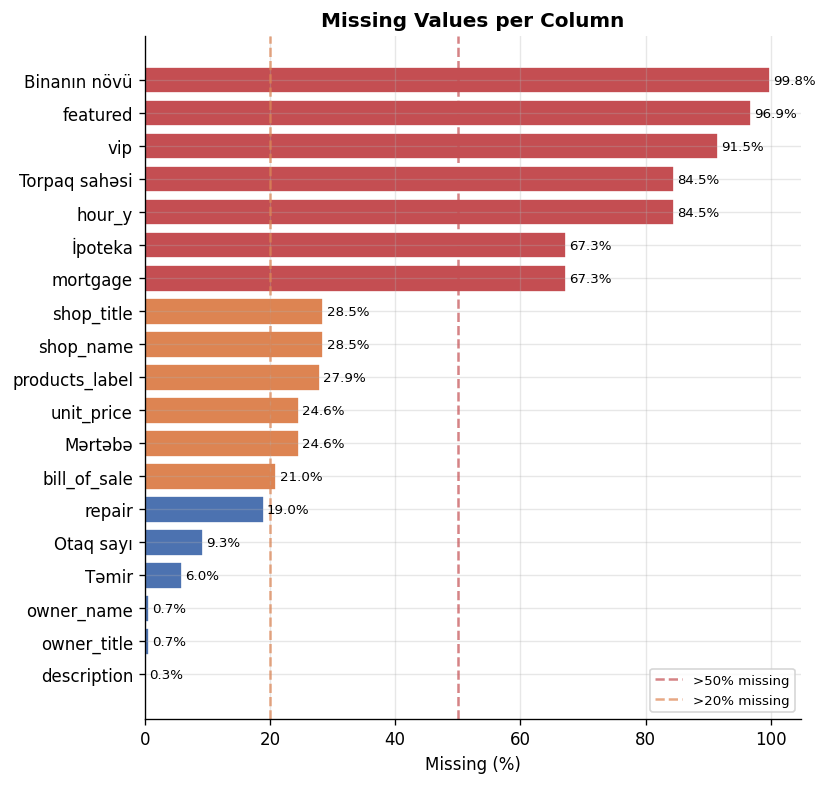

In [25]:
miss_pct = df_raw.isnull().mean().sort_values(ascending=False)
miss_pct = miss_pct[miss_pct > 0]

fig, ax = plt.subplots(figsize=(7, max(4, len(miss_pct) * 0.35)))
colors = ['#C44E52' if v > 0.5 else '#DD8452' if v > 0.2 else '#4C72B0' for v in miss_pct.values]
bars = ax.barh(miss_pct.index[::-1], miss_pct.values[::-1] * 100,
               color=colors[::-1], edgecolor='white')
for bar, val in zip(bars, miss_pct.values[::-1]):
    ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height() / 2,
            f'{val*100:.1f}%', va='center', fontsize=8)
ax.axvline(50, color='#C44E52', lw=1.5, linestyle='--', alpha=0.7, label='>50% missing')
ax.axvline(20, color='#DD8452', lw=1.5, linestyle='--', alpha=0.7, label='>20% missing')
ax.set_xlabel('Missing (%)')
ax.set_title('Missing Values per Column', fontweight='bold')
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(f'{FIG_DIR}/missing_values.png', bbox_inches='tight', dpi=150)
plt.show()

## 5. Outlier Box Plots

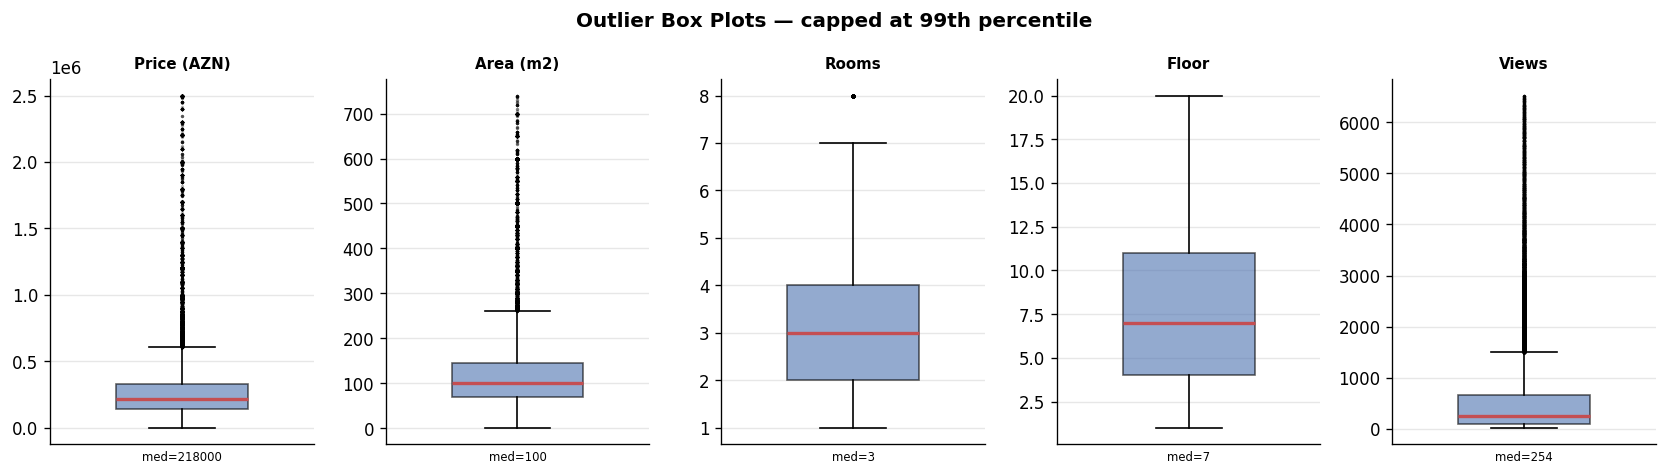

In [26]:
def parse_m2(s):
    try: return float(str(s).replace('m2','').replace('m²','').replace(',','.').strip())
    except: return np.nan

def parse_rooms(s):
    try: return float(str(s).split()[0])
    except: return np.nan

def parse_floor(s):
    try: return float(str(s).split('/')[0].strip())
    except: return np.nan

df_raw['area_m2'] = df_raw['Sahə'].apply(parse_m2)
df_raw['rooms']   = df_raw['Otaq sayı'].apply(parse_rooms)
df_raw['floor']   = df_raw['Mərtəbə'].apply(parse_floor)

numeric_feats = {
    'Price (AZN)': df_raw['price'],
    'Area (m2)':   df_raw['area_m2'],
    'Rooms':       df_raw['rooms'],
    'Floor':       df_raw['floor'],
    'Views':       df_raw['views'],
}

fig, axes = plt.subplots(1, 5, figsize=(14, 4))
for ax, (label, series) in zip(axes, numeric_feats.items()):
    data = series.dropna()
    cap = data.quantile(0.99)
    ax.boxplot(data[data <= cap], patch_artist=True, widths=0.5,
               boxprops=dict(facecolor=PALETTE[0], alpha=0.6),
               medianprops=dict(color=PALETTE[3], linewidth=2),
               flierprops=dict(marker='.', markersize=2, alpha=0.3))
    q1, med, q3 = data.quantile(0.25), data.median(), data.quantile(0.75)
    ax.set_title(label, fontsize=9, fontweight='bold')
    ax.set_xticks([])
    ax.set_xlabel(f'med={med:.0f}', fontsize=7)

fig.suptitle('Outlier Box Plots — capped at 99th percentile', fontweight='bold')
fig.tight_layout()
fig.savefig(f'{FIG_DIR}/outlier_boxplots.png', bbox_inches='tight', dpi=150)
plt.show()

## 6. Feature Correlation Matrix

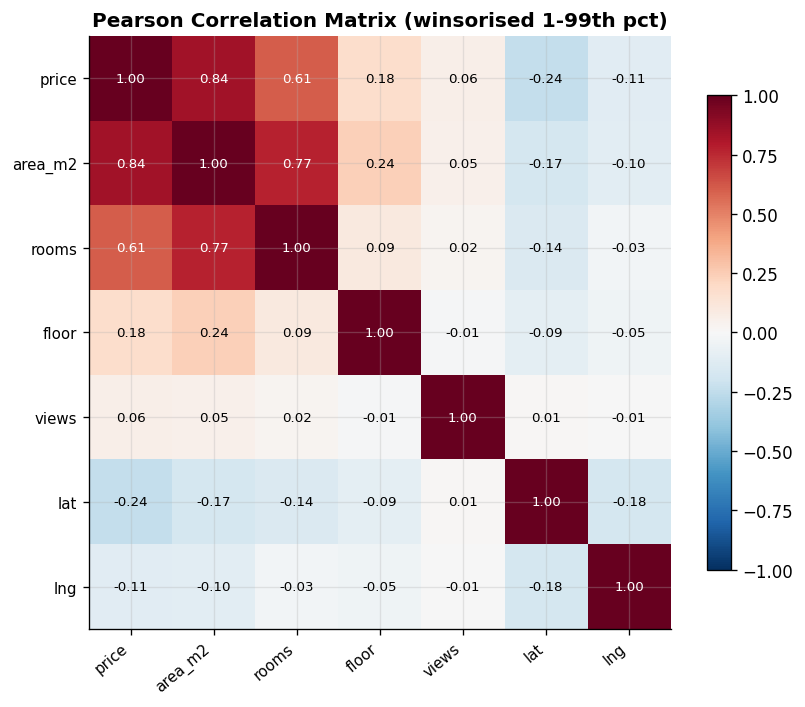

Correlations with price:
area_m2    0.841789
rooms      0.605863
lat       -0.239431
floor      0.178050
lng       -0.113440
views      0.057199
Name: price, dtype: float64


In [27]:
corr_cols = ['price', 'area_m2', 'rooms', 'floor', 'views', 'lat', 'lng']
corr_df = df_raw[corr_cols].dropna().copy()
for col in corr_cols:
    corr_df[col] = corr_df[col].clip(corr_df[col].quantile(0.01), corr_df[col].quantile(0.99))

corr_matrix = corr_df.corr()

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr_matrix, cmap='RdBu_r', vmin=-1, vmax=1, aspect='auto')
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_xticks(range(len(corr_cols)))
ax.set_yticks(range(len(corr_cols)))
ax.set_xticklabels(corr_cols, rotation=40, ha='right', fontsize=9)
ax.set_yticklabels(corr_cols, fontsize=9)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        val = corr_matrix.iloc[i, j]
        ax.text(j, i, f'{val:.2f}', ha='center', va='center',
                fontsize=8, color='white' if abs(val) > 0.5 else 'black')

ax.set_title('Pearson Correlation Matrix (winsorised 1-99th pct)', fontweight='bold')
fig.tight_layout()
fig.savefig(f'{FIG_DIR}/correlation_matrix.png', bbox_inches='tight', dpi=150)
plt.show()
print('Correlations with price:')
print(corr_matrix['price'].drop('price').sort_values(key=abs, ascending=False))

## 7. Price by City & Top Baku Districts

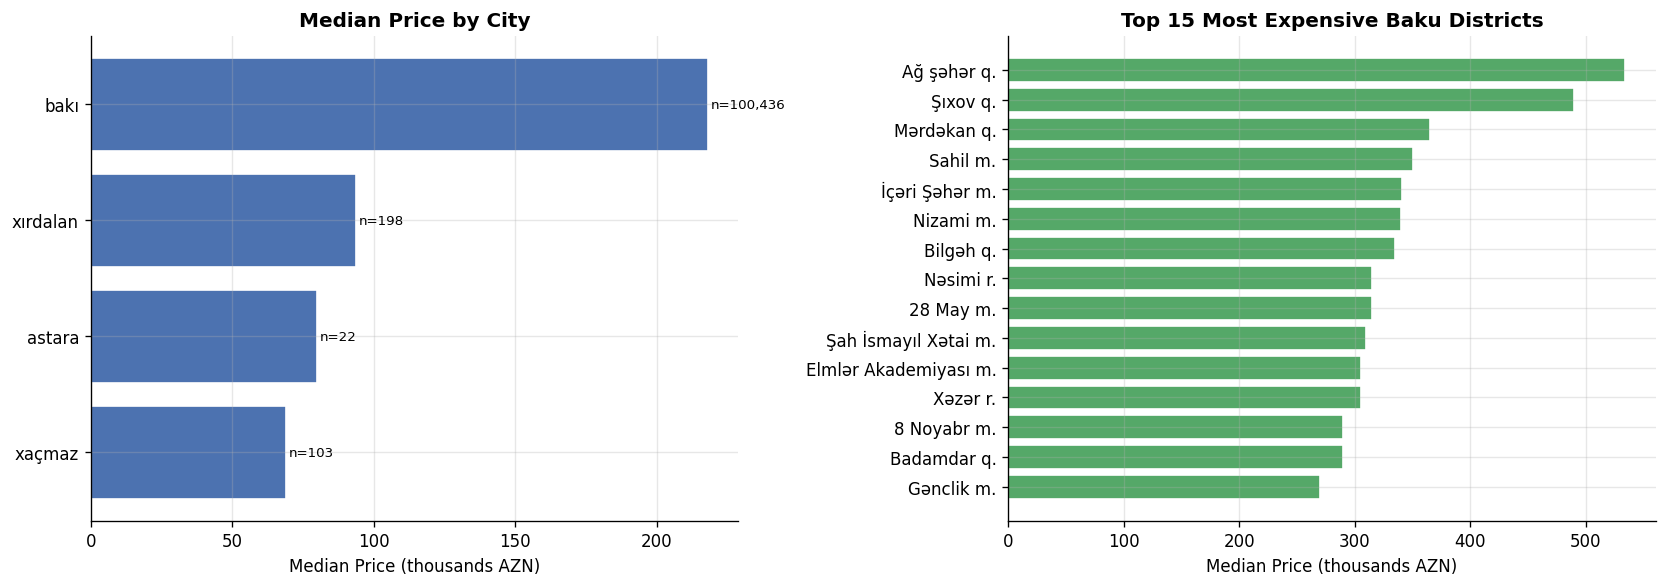

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

city_stats = (df_raw.groupby('city')['price']
              .agg(['median','count']).query('count >= 10')
              .sort_values('median', ascending=True))
axes[0].barh(city_stats.index, city_stats['median'] / 1e3,
             color=PALETTE[0], edgecolor='white')
for i, (idx, row) in enumerate(city_stats.iterrows()):
    axes[0].text(row['median'] / 1e3 + 1, i, f"n={row['count']:,.0f}", va='center', fontsize=8)
axes[0].set_xlabel('Median Price (thousands AZN)')
axes[0].set_title('Median Price by City', fontweight='bold')

baku = df_raw[df_raw['city'] == 'baku' if 'baku' in df_raw['city'].values else df_raw['city'] == 'bakı'].copy()
loc_stats = (baku.groupby('location')['price']
             .agg(['median','count']).query('count >= 50')
             .nlargest(15, 'median').sort_values('median', ascending=True))
axes[1].barh(loc_stats.index, loc_stats['median'] / 1e3,
             color=PALETTE[2], edgecolor='white')
axes[1].set_xlabel('Median Price (thousands AZN)')
axes[1].set_title('Top 15 Most Expensive Baku Districts', fontweight='bold')

fig.tight_layout()
fig.savefig(f'{FIG_DIR}/price_by_location.png', bbox_inches='tight', dpi=150)
plt.show()

## 8. Price-Tier Class Balance (Task B)

Running full pipeline...


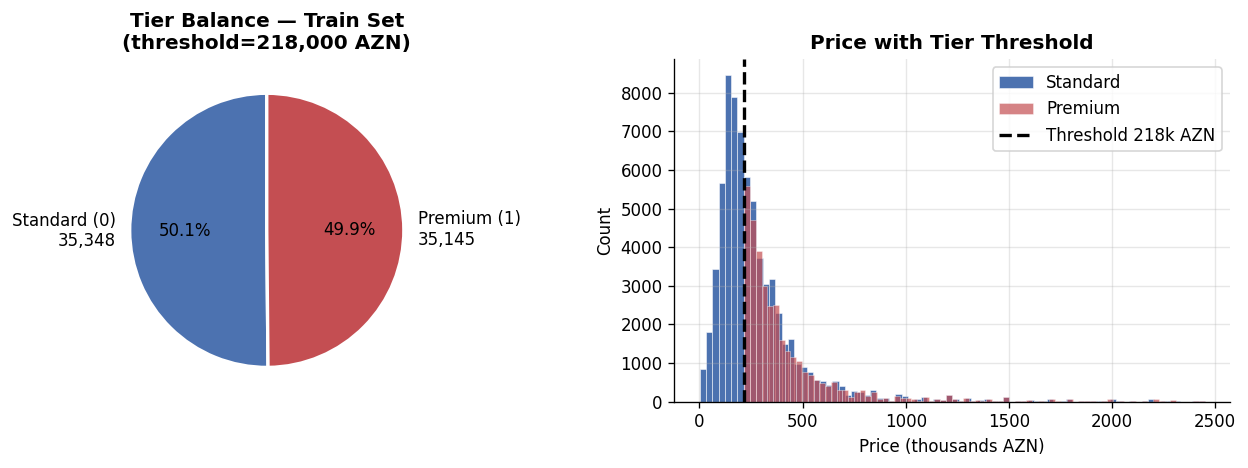

Standard: 35,348 (50.1%)  |  Premium: 35,145 (49.9%)


In [29]:
from src.data_prep import prepare_data
print('Running full pipeline...')
d = prepare_data()
THRESHOLD = d['tier_threshold']

tier_train = d['y_tier_train']
n_premium  = int(tier_train.sum())
n_standard = int((tier_train == 0).sum())
total      = len(tier_train)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].pie([n_standard, n_premium],
            labels=[f'Standard (0)\n{n_standard:,}', f'Premium (1)\n{n_premium:,}'],
            colors=[PALETTE[0], PALETTE[3]],
            autopct='%1.1f%%', startangle=90,
            wedgeprops=dict(edgecolor='white', linewidth=2))
axes[0].set_title(f'Tier Balance — Train Set\n(threshold={THRESHOLD:,.0f} AZN)', fontweight='bold')

prices_tr = d['y_train']
cap = np.percentile(prices_tr, 99)
axes[1].hist(prices_tr[prices_tr <= cap] / 1e3, bins=80,
             color=PALETTE[0], edgecolor='white', linewidth=0.3, label='Standard')
mask = (prices_tr <= cap) & (prices_tr > THRESHOLD)
axes[1].hist(prices_tr[mask] / 1e3, bins=80,
             color=PALETTE[3], edgecolor='white', linewidth=0.3, alpha=0.7, label='Premium')
axes[1].axvline(THRESHOLD / 1e3, color='black', lw=2, linestyle='--',
                label=f'Threshold {THRESHOLD/1e3:.0f}k AZN')
axes[1].set_xlabel('Price (thousands AZN)')
axes[1].set_ylabel('Count')
axes[1].set_title('Price with Tier Threshold', fontweight='bold')
axes[1].legend()

fig.tight_layout()
fig.savefig(f'{FIG_DIR}/tier_balance.png', bbox_inches='tight', dpi=150)
plt.show()
print(f'Standard: {n_standard:,} ({n_standard/total:.1%})  |  Premium: {n_premium:,} ({n_premium/total:.1%})')

## 9. Price vs Area & Rooms

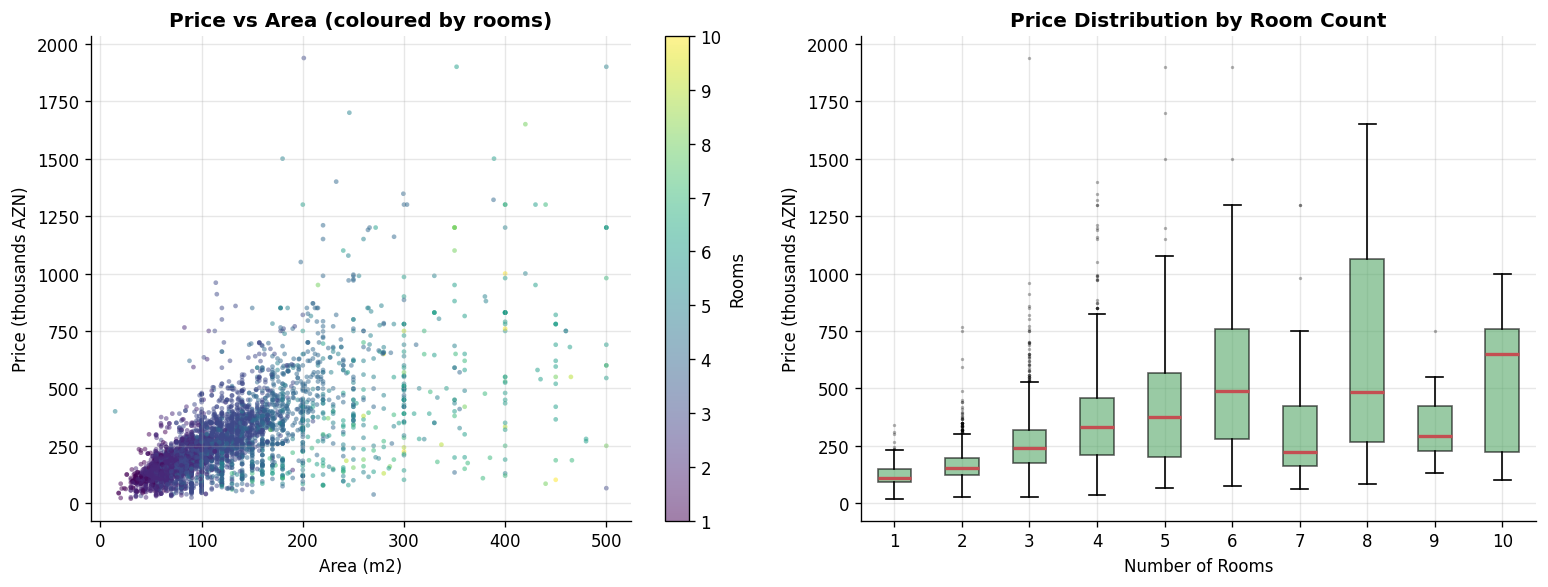

In [30]:
sample = df_raw[['price', 'area_m2', 'rooms']].dropna()
sample = sample[
    sample['price'].between(10_000, 2_000_000) &
    sample['area_m2'].between(10, 500) &
    sample['rooms'].between(1, 10)
].sample(5000, random_state=SEED)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sc = axes[0].scatter(sample['area_m2'], sample['price'] / 1e3,
                     c=sample['rooms'], cmap='viridis',
                     s=8, alpha=0.5, linewidths=0)
fig.colorbar(sc, ax=axes[0], label='Rooms')
axes[0].set_xlabel('Area (m2)')
axes[0].set_ylabel('Price (thousands AZN)')
axes[0].set_title('Price vs Area (coloured by rooms)', fontweight='bold')

room_groups = [sample[sample['rooms'] == r]['price'].values / 1e3
               for r in sorted(sample['rooms'].unique())]
room_labels = [str(int(r)) for r in sorted(sample['rooms'].unique())]
axes[1].boxplot(room_groups, labels=room_labels, patch_artist=True, widths=0.5,
                boxprops=dict(facecolor=PALETTE[2], alpha=0.6),
                medianprops=dict(color=PALETTE[3], linewidth=2),
                flierprops=dict(marker='.', markersize=2, alpha=0.3))
axes[1].set_xlabel('Number of Rooms')
axes[1].set_ylabel('Price (thousands AZN)')
axes[1].set_title('Price Distribution by Room Count', fontweight='bold')

fig.tight_layout()
fig.savefig(f'{FIG_DIR}/price_vs_area_rooms.png', bbox_inches='tight', dpi=150)
plt.show()

## 10. EDA Takeaways

| Finding | Implication |
|---|---|
| Price is **heavily right-skewed** | Use **log(price)** as Task A regression target |
| **Geospatial clusters** — Sabail, Nasimi are most expensive | `lat`/`lng` are strong predictors |
| `area_m2` correlates ~0.5 with price | Top feature after location |
| `Binanin novu` is 99.8% missing | Drop — already handled in data_prep |
| `Torpaq sahesi` is 84.5% missing | Imputed / flagged as missing |
| Tier split is **near 50/50** | Balanced — accuracy is a fair metric for Task B |
| Luxury outliers (>1M AZN) are sparse | Tree may struggle; flag in error analysis |
| 99.7% listings from **Baku** | District matters more than city |


In [31]:
import glob
figs = sorted(glob.glob(f'{FIG_DIR}/*.png'))
print(f'Saved {len(figs)} figures to {FIG_DIR}/')
for f in figs:
    print(' ', os.path.basename(f))

Saved 8 figures to ../report/figures/
  correlation_matrix.png
  geospatial_price_map.png
  missing_values.png
  outlier_boxplots.png
  price_by_location.png
  price_distribution.png
  price_vs_area_rooms.png
  tier_balance.png
